# Titanic test/train split

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('data/titanic_cabinReduced.csv')

## Data inspection

In [3]:
print(df.isna().sum())
print(df.dtypes)

Unnamed: 0         0
pclass             0
survived           0
name               0
sex                0
age              263
sibsp              0
parch              0
ticket             0
fare               1
cabin           1014
embarked           2
boat             823
body            1188
home.dest        564
CabinReduced    1014
dtype: int64
Unnamed: 0        int64
pclass          float64
survived          int64
name                str
sex                 str
age             float64
sibsp           float64
parch           float64
ticket              str
fare            float64
cabin               str
embarked            str
boat                str
body            float64
home.dest           str
CabinReduced        str
dtype: object


In [4]:
display(df.describe(include='all'))

,Unnamed: 0,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest,CabinReduced
count,1309.000000,1309.000000,1309.000000,1309,1309,1046.000000,1309.000000,1309.000000,1309,1308.000000,295,1307,486,121.000000,745,295
unique,NaN,NaN,NaN,1307,2,NaN,NaN,NaN,929,NaN,186,3,27,NaN,369,8
top,NaN,NaN,NaN,"Connolly, Miss. Kate",male,NaN,NaN,NaN,CA. 2343,NaN,C23 C25 C27,S,13,NaN,"New York, NY",C
freq,NaN,NaN,NaN,2,843,NaN,NaN,NaN,11,NaN,6,914,39,NaN,64,94
mean,654.000000,2.294882,0.381971,NaN,NaN,29.881135,0.498854,0.385027,NaN,33.295479,NaN,NaN,NaN,160.809917,NaN,NaN
std,378.020061,0.837836,0.486055,NaN,NaN,14.413500,1.041658,0.865560,NaN,51.758668,NaN,NaN,NaN,97.696922,NaN,NaN
min,0.000000,1.000000,0.000000,NaN,NaN,0.166700,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,1.000000,NaN,NaN
25%,327.000000,2.000000,0.000000,NaN,NaN,21.000000,0.000000,0.000000,NaN,7.895800,NaN,NaN,NaN,72.000000,NaN,NaN
50%,654.000000,3.000000,0.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN,NaN,155.000000,NaN,NaN
75%,981.000000,3.000000,1.000000,NaN,NaN,39.000000,1.000000,0.000000,NaN,31.275000,NaN,NaN,NaN,256.000000,NaN,NaN


## Data split

In [5]:
col_name = ['cabin', 'CabinReduced', 'sex']
X = df[col_name]
y = df['survived']

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=67, stratify=y
)

print("==== stratify=y ====")
print(X_train.shape, X_test.shape)
print("Train:\n", y_train.value_counts(normalize=True))
print("Test:\n", y_test.value_counts(normalize=True))

==== stratify=y ====
(1047, 3) (262, 3)
Train:
 survived
0    0.617956
1    0.382044
Name: proportion, dtype: float64
Test:
 survived
0    0.618321
1    0.381679
Name: proportion, dtype: float64


In [7]:
X_train_ns, X_test_ns, y_train_ns, y_test_ns = train_test_split(
    X, y, test_size=0.2, random_state=67, stratify=None
)

print("\n=== stratify=None ===")
print(X_train_ns.shape, X_test_ns.shape)
print("Train:\n", y_train_ns.value_counts(normalize=True))
print("Test:\n", y_test_ns.value_counts(normalize=True))


=== stratify=None ===
(1047, 3) (262, 3)
Train:
 survived
0    0.619866
1    0.380134
Name: proportion, dtype: float64
Test:
 survived
0    0.610687
1    0.389313
Name: proportion, dtype: float64


* **`test_size`** – określa wielkość zbioru testowego. Jeśli podamy liczbę zmiennoprzecinkową z przedziału $(0, 1)$ (tutaj `0.2`), oznacza ona odsetek wszystkich obserwacji trafiających do zbioru testowego (20%). Jeśli podamy liczbę całkowitą, definiuje ona dokładną liczbę rekordów.
* **`random_state`** – ustawia ziarno generatora liczb pseudolosowych, co zapewnia powtarzalność podziału przy kolejnych uruchomieniach notatnika.
* **`stratify`** – wymusza losowanie warstwowe względem wskazanej zmiennej (tutaj zmiennej docelowej `y`), dzięki czemu udział klas w zbiorze treningowym i testowym jest niemal identyczny jak w całym zbiorze danych.

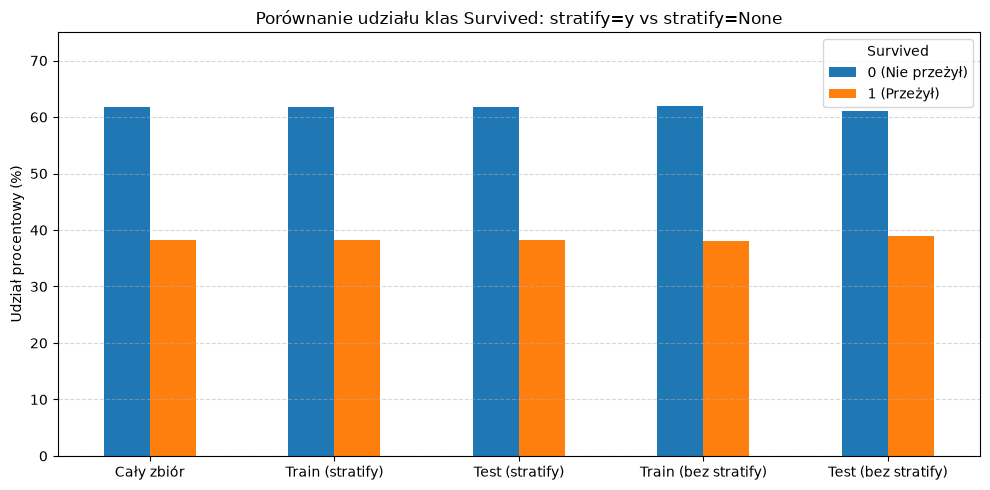

In [11]:
# 3. Zestawienie proporcji na jednym wykresie słupkowym
proporcje = pd.DataFrame({
    'Cały zbiór': y.value_counts(normalize=True) * 100,
    'Train (stratify)': y_train.value_counts(normalize=True) * 100,
    'Test (stratify)': y_test.value_counts(normalize=True) * 100,
    'Train (bez stratify)': y_train_ns.value_counts(normalize=True) * 100,
    'Test (bez stratify)': y_test_ns.value_counts(normalize=True) * 100,
}).T

ax = proporcje.plot(kind='bar', figsize=(10, 5), rot=0)
ax.set_title('Porównanie udziału klas Survived: stratify=y vs stratify=None')
ax.set_ylabel('Udział procentowy (%)')
ax.set_ylim(0, 75)
ax.legend(['0 (Nie przeżył)', '1 (Przeżył)'], title='Survived')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

W tym przypadku różnice między podziałem z parametrem stratify, a podziałem bez niego są niewielkie (ok. 0,9 p.p.), ponieważ zbiór jest stosunkowo duży, a klasy nie są skrajnie niezbalansowane. Stosowanie `stratify=y` jest dobrą praktyką,ponieważ gwarantuje reprezentatywność zmiennej docelowej w obu podzbiorach i zapobiega sytuacji, w której model uczy się na zaburzonych proporcjach klas.

In [9]:
for col in col_name:
    print(f'\n{col}:')
    print('Train:')
    print(X_train[col].value_counts(normalize=True))
    print('Test:')
    print(X_test[col].value_counts(normalize=True))


cabin:
Train:
cabin
B57 B59 B63 B66    0.021645
C22 C26            0.017316
C23 C25 C27        0.017316
F33                0.017316
D                  0.017316
                     ...   
C62 C64            0.004329
C55 C57            0.004329
A16                0.004329
D22                0.004329
C82                0.004329
Name: proportion, Length: 156, dtype: float64
Test:
cabin
B35            0.031250
G6             0.031250
C2             0.031250
C23 C25 C27    0.031250
B18            0.031250
E49            0.015625
C101           0.015625
C125           0.015625
E31            0.015625
B71            0.015625
E40            0.015625
B26            0.015625
C65            0.015625
A10            0.015625
C85            0.015625
C92            0.015625
B94            0.015625
D43            0.015625
C103           0.015625
C6             0.015625
D15            0.015625
C91            0.015625
A34            0.015625
B24            0.015625
D7             0.015625
C130         

Rozkład płci (`sex`) jest bardzo zbliżony w obu podzbiorach (~64,7% mężczyzn w zbiorze treningowym vs ~63,4% w testowym). W przypadku kolumny `cabin` występuje aż 156 unikalnych wartości w zbiorze treningowym, przez co wiele kabin pojawia się wyłącznie w zbiorze testowym (np. `'B35'`). W zredukowanej zmiennej `CabinReduced` proporcje głównych pokładów są zbliżone, jednak rzadka kategoria `'T'` trafiła wyłącznie do zbioru treningowego.

## Kodowanie zmiennych kategorycznych (LabelEncoder)

In [12]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
for col in col_name:
    encoder.fit(X_train[col].astype(str))
    X_train[col + '_map'] = encoder.transform(X_train[col].astype(str))
    X_test[col + '_map'] = encoder.transform(X_test[col].astype(str))

ValueError: y contains previously unseen labels: 'B35'

`LabelEncoder` uczy się mapowania wyłącznie na zbiorze treningowym (`X_train`). Ponieważ w kolumnie `cabin` występują pojedyncze numery kabin obecne tylko w `X_test` (np. `'B35'`), wywołanie `transform()` na zbiorze testowym kończy się błędem `ValueError: y contains previously unseen labels`. Aby kod zadziałał dla wszystkich pozostałych zmiennych, należy usunąć z listy kolumnę **`cabin`** o wysokiej kardynalności, dlatego też w poprzenim ćwiczeniu tworzyliśmy kolumnę CabinReduced.

In [17]:
encoder = LabelEncoder()
col_name = ['sex', 'CabinReduced']
for col in col_name:
    encoder.fit(X_train[col].astype(str))
    X_train[col + '_map'] = encoder.transform(X_train[col].astype(str))
    X_test[col + '_map'] = encoder.transform(X_test[col].astype(str))

In [18]:
print(X_train.isna().sum())
X_train.head(20)

cabin               816
CabinReduced        816
sex                   0
cabin_map             0
sex_map               0
CabinReduced_map      0
dtype: int64


,cabin,CabinReduced,sex,cabin_map,sex_map,CabinReduced_map
127,C123,C,female,56,0,2
190,D9,D,female,119,0,3
1079,NaN,NaN,female,156,0,8
667,NaN,NaN,female,156,0,8
731,NaN,NaN,male,156,1,8
657,NaN,NaN,female,156,0,8
940,NaN,NaN,male,156,1,8
1230,G6,G,female,154,0,6
259,NaN,NaN,male,156,1,8
1078,NaN,NaN,female,156,0,8


Po usunięciu `cabin` kodowanie przebiega poprawnie: wartości tekstowe w `sex` i `CabinReduced` zostały zastąpione liczbami całkowitymi (`0, 1` dla płci oraz `0–8` dla pokładów), a braki `NaN` — ze względu na wcześniejszą konwersję `.astype(str)` — zostały potraktowane jako osobna kategoria tekstowa `'nan'` (zakodowana jako `8`).

## Imputacja brakujących wartości

### Imputacja zerami

In [ ]:
X_train_0 = X_train.fillna(0)
X_test_0 = X_test.fillna(0)

print("Braki po imputacji (Train):\n", X_train_0.isna().sum())
print("\nRozkład CabinReduced po imputacji zerami (Train):")
print(X_train_0['CabinReduced'].value_counts(normalize=True))

Braki po imputacji (Train):
 cabin               0
CabinReduced        0
sex                 0
cabin_map           0
sex_map             0
CabinReduced_map    0
dtype: int64

Rozkład CabinReduced po imputacji zerami (Train):
CabinReduced
0    0.779370
C    0.067813
B    0.047755
D    0.034384
E    0.032474
F    0.018147
A    0.016237
G    0.002865
T    0.000955
Name: proportion, dtype: float64


### Imputacja dominantą (`SimpleImputer(strategy='most_frequent')`)

In [ ]:
from sklearn.impute import SimpleImputer

cols = ['cabin', 'CabinReduced', 'sex']
X_train_freq = X_train[cols].copy()
X_test_freq = X_test[cols].copy()

imputer = SimpleImputer(strategy='most_frequent')

X_train_freq[cols] = imputer.fit_transform(X_train_freq[cols])
X_test_freq[cols] = imputer.transform(X_test_freq[cols])

print("Braki po imputacji (Train):\n", X_train_freq.isna().sum())
print("\nRozkład CabinReduced po imputacji most_frequent (Train):")
print(X_train_freq['CabinReduced'].value_counts(normalize=True))

Braki po imputacji (Train):
 cabin           0
CabinReduced    0
sex             0
dtype: int64

Rozkład CabinReduced po imputacji most_frequent (Train):
CabinReduced
C    0.847182
B    0.047755
D    0.034384
E    0.032474
F    0.018147
A    0.016237
G    0.002865
T    0.000955
Name: proportion, dtype: float64


### Imputacja group-wise dominantą (względem płci)

In [ ]:
X_train_imp = X_train.copy()
X_test_imp = X_test.copy()

mode_by_sex = X_train_imp.groupby('sex')['CabinReduced'].agg(lambda s: s.mode().iloc[0])
print(mode_by_sex)

X_train_imp['CabinReduced'] = X_train_imp['CabinReduced'].fillna(X_train_imp['sex'].map(mode_by_sex))
X_test_imp['CabinReduced'] = X_test_imp['CabinReduced'].fillna(X_test_imp['sex'].map(mode_by_sex))

print("Braki po imputacji (Train):\n", X_train_imp.isna().sum())
print("\nRozkład CabinReduced po imputacji dominantą ze względu na płeć (Train):")
print(X_train_imp['CabinReduced'].value_counts(normalize=True))

sex
female    C
male      C
Name: CabinReduced, dtype: str
Braki po imputacji (Train):
 cabin               816
CabinReduced          0
sex                   0
cabin_map             0
sex_map               0
CabinReduced_map      0
dtype: int64

Rozkład CabinReduced po imputacji dominantą ze względu na płeć (Train):
CabinReduced
C    0.847182
B    0.047755
D    0.034384
E    0.032474
F    0.018147
A    0.016237
G    0.002865
T    0.000955
Name: proportion, dtype: float64


**Porównanie metod imputacji oraz dobór względem typu zmiennej:**
* **`fillna(0)` vs `fillna('brak danych')`:** Obie metody tworzą dla braków osobną, jawną kategorię, dzięki czemu nie zniekształcają rozkładu istniejących pokładów (udział pokładu `'C'` pozostaje na poziomie ~6,8% całego zbioru). Jednak `fillna('brak danych')` zachowuje spójny typ danych na przestrzeni całej kolumny(`str`).
* **`SimpleImputer(strategy='most_frequent')` oraz imputacja dominantą w grupach (`sex`):** Wypełnienie braków najczęstszą wartością nadaje się do zmiennych kategorycznych, jednak przy tak dużym odsetku braków (~78%) prowadzi do silnego zaburzenia rozkładu — udział pokładu `'C'` rośnie sztucznie z ~6,8% do 84,7%. Imputacja warunkowa względem płci dała identyczny rezultat, ponieważ dominanta dla kobiet i mężczyzn jest taka sama (`'C'`). Lepszą zmienną grupującą mogłaby być klasa pasażera (`pclass`), której nie używamy w tym ćwiczeniu.
* **`SimpleImputer(strategy='median')`, `KNNImputer` oraz `IterativeImputer`:** Metody te opierają się na obliczeniach matematycznych (kwantylach, odległościach między obserwacjami lub regresji), dlatego **nie nadają się do imputacji surowych danych jakościowych** i zwrócą błąd na kolumnach tekstowych. Nawet po zakodowaniu kategorii na liczby całkowite (`LabelEncoder`) ich użycie dla zmiennych nominalnych byłoby błędem, ponieważ algorytmy te traktowałyby numery etykiet jak wartości ciągłe posiadające porządek i dystans, a LabelEncoder przypisał je arbitralnie.

## Porównanie liczby unikalnych wartości przed i po kodowaniu

In [19]:
porownanie_unikalnych = pd.DataFrame({
    'Train (przed - bez NaN)': X_train[['sex', 'CabinReduced']].nunique(dropna=True),
    'Train (przed - z NaN)': X_train[['sex', 'CabinReduced']].nunique(dropna=False),
    'Train (po LabelEncoder)': X_train[['sex_map', 'CabinReduced_map']].nunique().values,
    'Test (przed - bez NaN)': X_test[['sex', 'CabinReduced']].nunique(dropna=True),
    'Test (przed - z NaN)': X_test[['sex', 'CabinReduced']].nunique(dropna=False),
    'Test (po LabelEncoder)': X_test[['sex_map', 'CabinReduced_map']].nunique().values,
})

display(porownanie_unikalnych)

,Train (przed - bez NaN),Train (przed - z NaN),Train (po LabelEncoder),Test (przed - bez NaN),Test (przed - z NaN),Test (po LabelEncoder)
sex,2,2,2,2,2,2
CabinReduced,8,9,9,7,8,8


Dla zmiennej `sex` (brak wartości `NaN`) liczba unikalnych wartości przed i po kodowaniu jest identyczna i wynosi **2** w obu zbiorach.

W przypadku `CabinReduced` liczba unikalnych wartości po kodowaniu wzrosła o **1** względem liczby niepustych kategorii (z 8 do **9** w `X_train` oraz z 7 do **8** w `X_test`). Wynika to z użycia `.astype(str)` przed dopasowaniem `LabelEncoder` — wartości `NaN` zostały zamienione na napis `'nan'` i zakodowane jako osobna klasa (`8`). Dodatkowo po imputacji dominantą (`most_frequent`) liczba unikalnych wartości w `CabinReduced` maleje o 1 (do 8 w `X_train` i 7 w `X_test`), ponieważ braki zostają zastąpione przez najczęstszą kategorię `'C'`.

## Wnioski końcowe

1. **Reprezentatywność zbiorów treningowego i testowego:**
   Dla cech o niskiej liczbie kategorii (np. `sex`) losowy podział 80/20 dobrze odwzorowuje strukturę populacji w obu podzbiorach. Problem pojawia się przy cechach o wysokiej kardynalności lub bardzo rzadkich klasach (`cabin`, kategoria `'T'` w `CabinReduced`), gdzie pojedyncze obserwacje trafiają wyłącznie do jednego ze zbiorów.

2. **Wpływ imputacji braków i kodowania (labelingu):**
   * *Imputacja:* Wybór metody silnie wpływa na rozkład zmiennej. Przy wysokim odsetku braków (~78% w `CabinReduced`) zastąpienie ich dominantą (`most_frequent`) sztucznie zawyża udział najczęstszej klasy i zaciera informację o samym fakcie braku danych. Utworzenie osobnej kategorii (`fillna(0)` lub `fillna('brak danych')`) zachowuje oryginalne proporcje znanych pokładów i pozwala modelowi wykorzystać informację o braku przypisanej kabiny.
   * *Kodowanie (`LabelEncoder`):* Kodowanie jest istotne, ale wiąże się z dwoma istotnymi efektami:
    - `LabelEncoder` dopasowany wyłącznie do `X_train` nie obsługuje nowych etykiet pojawiających się w `X_test` (dlatego do encodowania nie nadawała się kolumna `cabin`)
    -  `LabelEncoder` narzuca zmiennym nominalnym sztuczny porządek liczbowy ($0 < 1 < \dots < 8$), co dla modeli liniowych czy opartych na odległościach (np. kNN) wymagałoby raczej użycia OneHotEncoder`, w modelach drzewiastych jest to akceptowalne.

3. **Znaczenie stratyfikacji przy podziale danych:**
   Parametr `stratify=y` gwarantuje zachowanie identycznych proporcji zmiennej docelowej (`survived`) w zbiorze treningowym i testowym. Zapobiega to obciążeniu procesu uczenia oraz zafałszowaniu metryk ewaluacji, co ma kluczowe znaczenie zwłaszcza w zbiorach niezbalansowanych lub o małej liczbie obserwacji.

## Zastosowanie AI

Sztuczna inteligencja została wykorzystane do uporządkowania struktury notatnika (usunięcia zbędnych komórek testowych) oraz redakcji i sformatowania w Markdownie wyciągnietych wniosków.